In [7]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Project root
PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT))

from npr_method.npr import collect_differences

In [8]:
DATA_DIR = PROJECT_ROOT / "data"

real_paths = list((DATA_DIR / "real").glob("*"))
fake_paths = list((DATA_DIR / "fake").glob("*"))

print(f"Real images: {len(real_paths)}")
print(f"Fake images: {len(fake_paths)}")

Real images: 50
Fake images: 50


In [9]:
rng = np.random.default_rng(42)

# Split each dataset into two random groups.
real_split = np.array_split(rng.permutation(real_paths), 2)
fake_split = np.array_split(rng.permutation(fake_paths), 2)

real_1 = collect_differences(real_split[0].tolist())
real_2 = collect_differences(real_split[1].tolist())

fake_1 = collect_differences(fake_split[0].tolist())
fake_2 = collect_differences(fake_split[1].tolist())

print(f"Real groups: {len(real_split[0])} / {len(real_split[1])}")
print(f"Fake groups: {len(fake_split[0])} / {len(fake_split[1])}")

Real groups: 25 / 25
Fake groups: 25 / 25


In [10]:
real_differences = collect_differences(real_paths)
fake_differences = collect_differences(fake_paths)

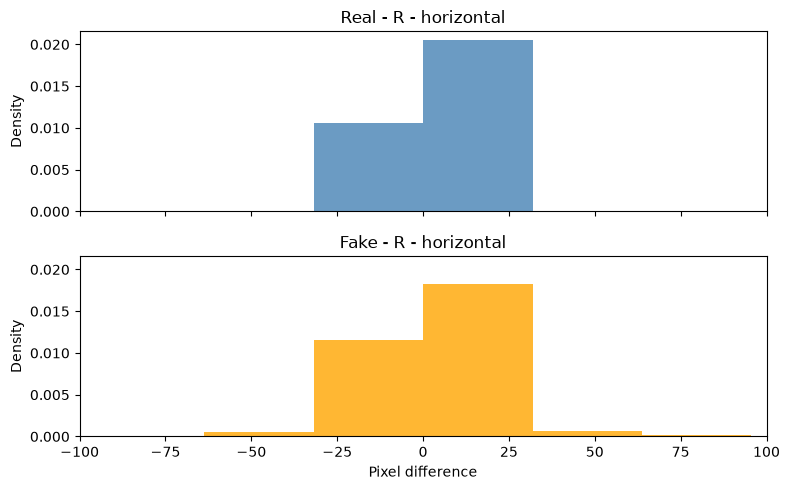

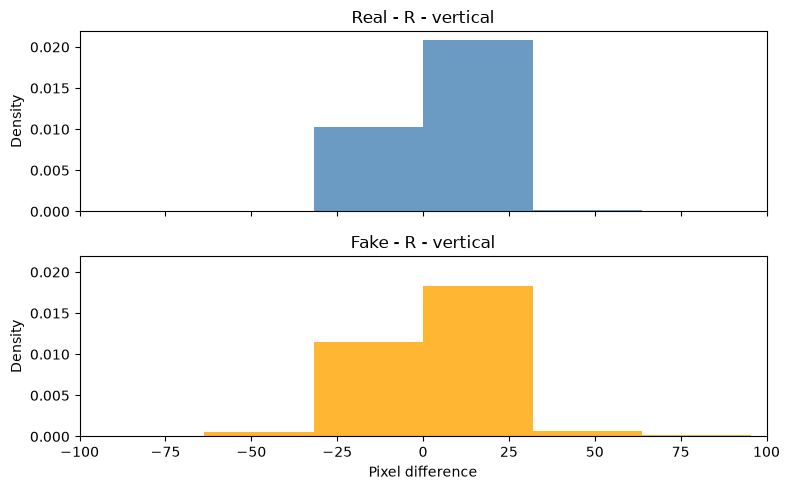

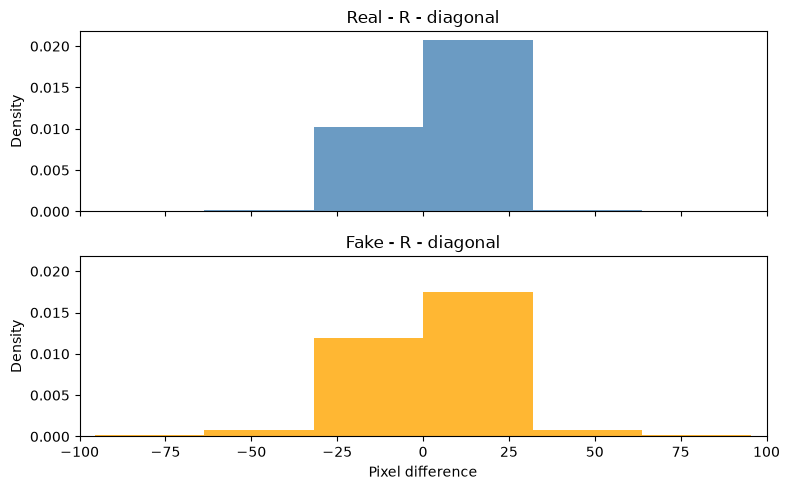

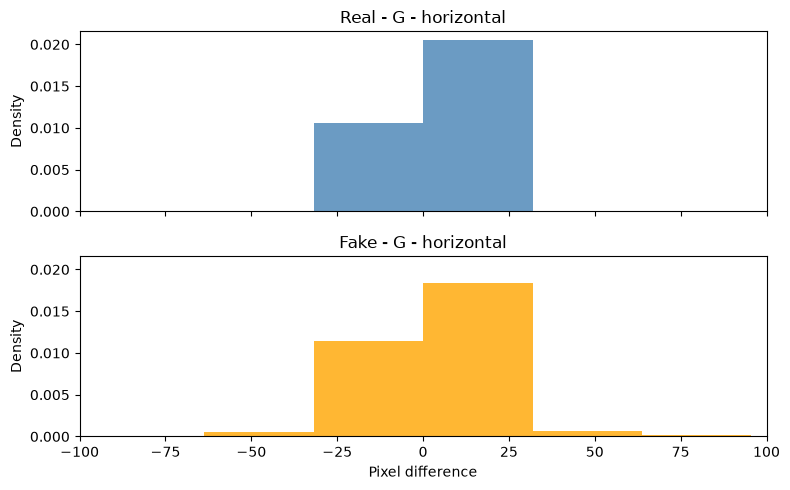

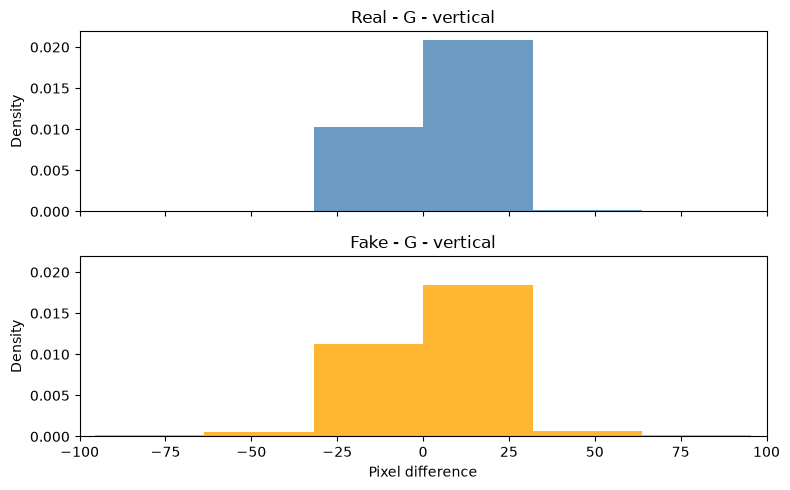

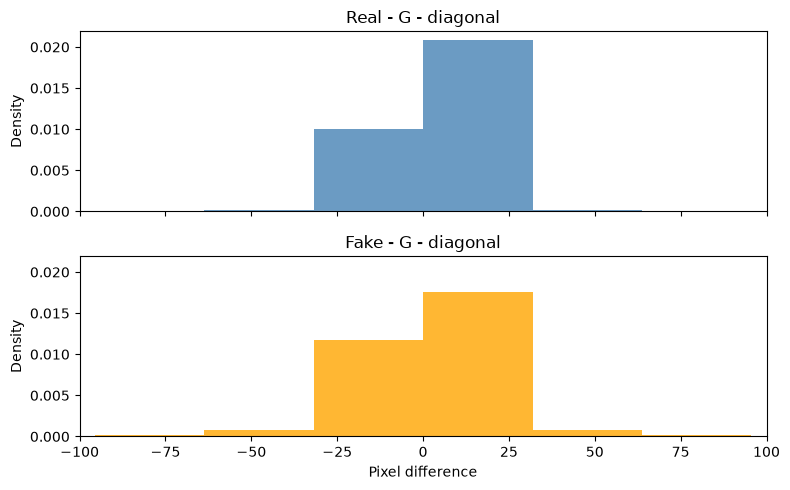

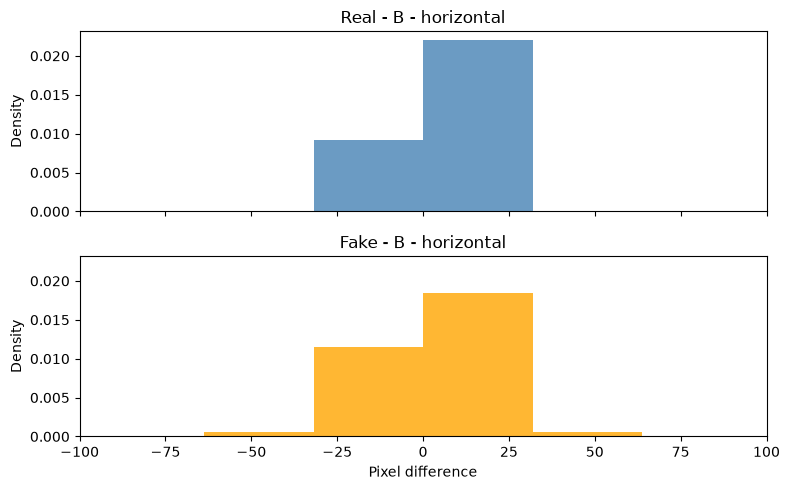

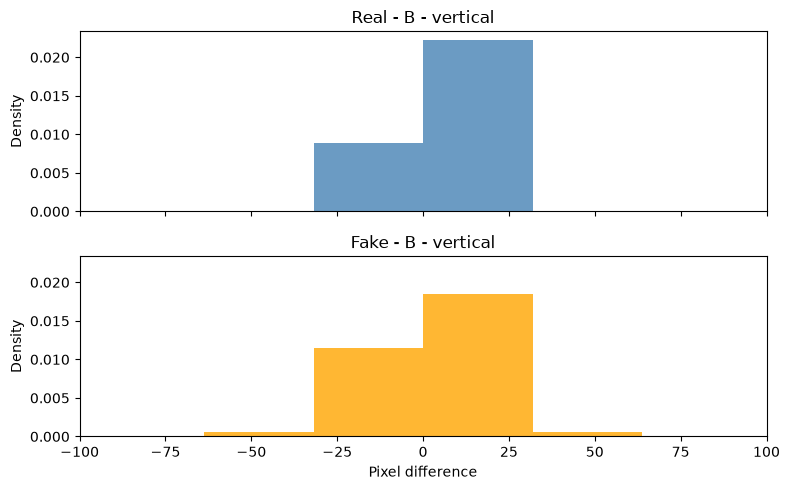

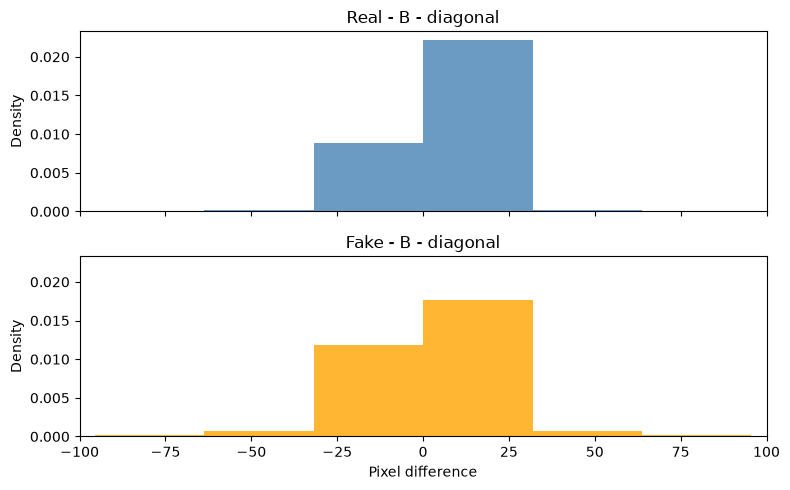

In [11]:
channels = ["R", "G", "B"]
directions = ["horizontal", "vertical", "diagonal"]

bins = np.linspace(-255, 255, 17)

for channel in channels:
    for direction in directions:

        real = real_differences[channel][direction]
        fake = fake_differences[channel][direction]

        fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, sharey=True)

        # Real
        axes[0].hist(
            real,
            bins=bins,
            density=True,
            color="steelblue",
            alpha=0.8
        )
        axes[0].set_title(f"Real - {channel} - {direction}")
        axes[0].set_ylabel("Density")

        # Fake
        axes[1].hist(
            fake,
            bins=bins,
            density=True,
            color="orange",
            alpha=0.8
        )
        axes[1].set_title(f"Fake - {channel} - {direction}")
        axes[1].set_xlabel("Pixel difference")
        axes[1].set_ylabel("Density")

        axes[0].set_xlim(-100, 100)
        axes[1].set_xlim(-100, 100)

        plt.tight_layout()
        plt.show()

In [12]:
import pandas as pd

N_SEEDS = 20
BINS = np.linspace(-255, 255, 17)

channels = ["R", "G", "B"]
directions = ["horizontal", "vertical", "diagonal"]

comparisons = [
    "Real 1 - Real 2",
    "Fake 1 - Fake 2",
    "Real 1 - Fake 2",
    "Real 2 - Fake 1"
]

# Store distances for each channel and direction.
results = {
    (channel, direction): {
        comparison: []
        for comparison in comparisons
    }
    for channel in channels
    for direction in directions
}


def normalized_histogram(values):
    hist, _ = np.histogram(values, bins=BINS)
    return hist / values.size


def histogram_distance(hist_1, hist_2):
    return np.sum(np.abs(hist_1 - hist_2))


# Repeat the experiment with different random splits.
for seed in range(N_SEEDS):
    rng = np.random.default_rng(seed)

    real_split = np.array_split(rng.permutation(real_paths), 2)
    fake_split = np.array_split(rng.permutation(fake_paths), 2)

    real_1 = collect_differences(real_split[0].tolist())
    real_2 = collect_differences(real_split[1].tolist())

    fake_1 = collect_differences(fake_split[0].tolist())
    fake_2 = collect_differences(fake_split[1].tolist())

    for channel in channels:
        for direction in directions:

            # Compute the four normalized histograms.
            histograms = {
                "Real 1": normalized_histogram(
                    real_1[channel][direction]
                ),
                "Real 2": normalized_histogram(
                    real_2[channel][direction]
                ),
                "Fake 1": normalized_histogram(
                    fake_1[channel][direction]
                ),
                "Fake 2": normalized_histogram(
                    fake_2[channel][direction]
                )
            }

            pairs = [
                ("Real 1", "Real 2"),
                ("Fake 1", "Fake 2"),
                ("Real 1", "Fake 2"),
                ("Real 2", "Fake 1")
            ]

            for comparison, (group_1, group_2) in zip(
                comparisons, pairs
            ):
                distance = histogram_distance(
                    histograms[group_1],
                    histograms[group_2]
                )

                results[(channel, direction)][comparison].append(
                    distance
                )


In [13]:
for channel in channels:
    for direction in directions:

        rows = []

        for comparison in comparisons:
            distances = results[(channel, direction)][comparison]

            rows.append({
                "Comparison": comparison,
                "Mean distance": np.mean(distances),
                "Std": np.std(distances, ddof=1)
            })

        df = pd.DataFrame(rows)

        print(f"\n{channel} - {direction}")
        display(df.round(4))


R - horizontal


,Comparison,Mean distance,Std
0,Real 1 - Real 2,0.0375,0.0330
1,Fake 1 - Fake 2,0.0324,0.0253
2,Real 1 - Fake 2,0.1530,0.0305
3,Real 2 - Fake 1,0.1317,0.0300



R - vertical


,Comparison,Mean distance,Std
0,Real 1 - Real 2,0.0415,0.0315
1,Fake 1 - Fake 2,0.0303,0.0226
2,Real 1 - Fake 2,0.1762,0.0302
3,Real 2 - Fake 1,0.1511,0.0302



R - diagonal


,Comparison,Mean distance,Std
0,Real 1 - Real 2,0.0441,0.0332
1,Fake 1 - Fake 2,0.0322,0.0235
2,Real 1 - Fake 2,0.2210,0.0322
3,Real 2 - Fake 1,0.1973,0.0322


... (8 outputs left out)


B - vertical


,Comparison,Mean distance,Std
0,Real 1 - Real 2,0.0460,0.0352
1,Fake 1 - Fake 2,0.0320,0.0243
2,Real 1 - Fake 2,0.2491,0.0384
3,Real 2 - Fake 1,0.2346,0.0384



B - diagonal


,Comparison,Mean distance,Std
0,Real 1 - Real 2,0.0506,0.0342
1,Fake 1 - Fake 2,0.0335,0.0252
2,Real 1 - Fake 2,0.2994,0.0409
3,Real 2 - Fake 1,0.2842,0.0410


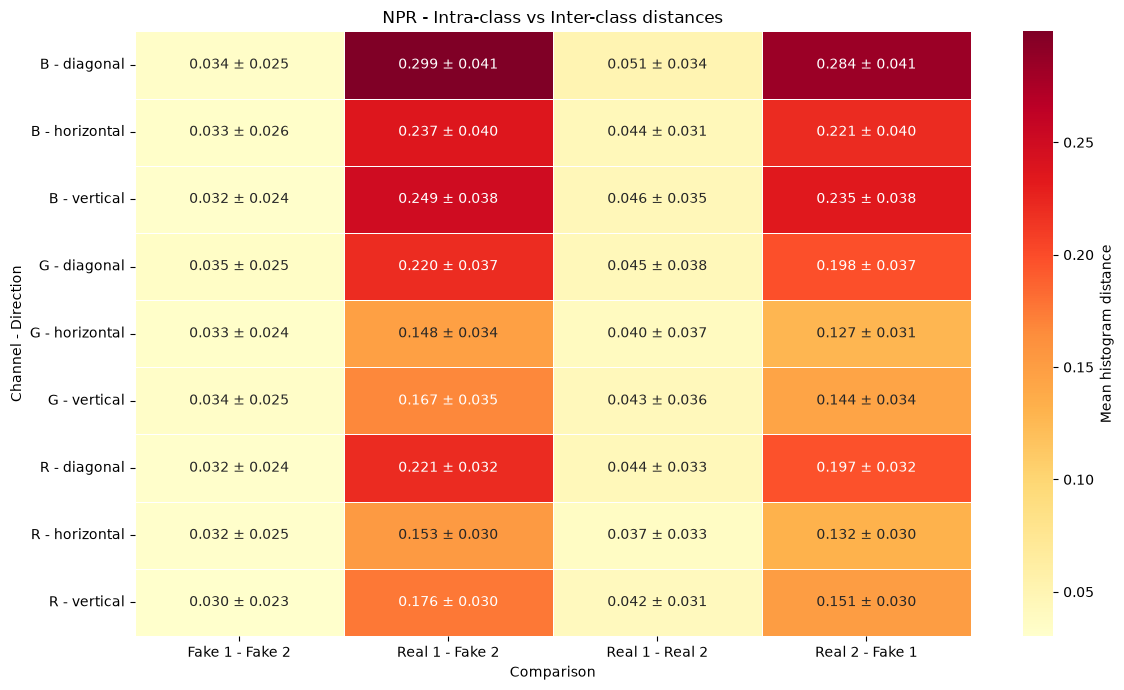

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

comparisons_heatmap = [
    "Real 1 - Real 2",
    "Fake 1 - Fake 2",
    "Real 1 - Fake 2",
    "Real 2 - Fake 1"
]

data = []

for channel in channels:
    for direction in directions:
        for comparison in comparisons_heatmap:
            distances = results[(channel, direction)][comparison]

            data.append({
                "Feature": f"{channel} - {direction}",
                "Comparison": comparison,
                "Mean": np.mean(distances),
                "Std": np.std(distances, ddof=1)
            })

df_heatmap = pd.DataFrame(data)

pivot_mean = df_heatmap.pivot(
    index="Feature",
    columns="Comparison",
    values="Mean"
)

pivot_std = df_heatmap.pivot(
    index="Feature",
    columns="Comparison",
    values="Std"
)

annotations = pivot_mean.copy().astype(object)

for i in range(pivot_mean.shape[0]):
    for j in range(pivot_mean.shape[1]):
        annotations.iloc[i, j] = (
            f"{pivot_mean.iloc[i, j]:.3f} ± {pivot_std.iloc[i, j]:.3f}"
        )

plt.figure(figsize=(12, 7))

sns.heatmap(
    pivot_mean,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Mean histogram distance"}
)

plt.title("NPR - Intra-class vs Inter-class distances")
plt.xlabel("Comparison")
plt.ylabel("Channel - Direction")
plt.tight_layout()
plt.show()